In [12]:

from pathlib import Path
import pandas as pd

carpeta_datos = Path("../data/processed")

peliculas = pd.read_csv(
    carpeta_datos / "peliculas_analisis.csv"
)

series = pd.read_csv(
    carpeta_datos / "series_analisis.csv"
)

# Unir ambos conjuntos para analizar el catálogo completo
catalogo = pd.concat(
    [peliculas, series],
    ignore_index=True
)

print("Total de registros:", len(catalogo))
print("\nDistribución por tipo:")
print(catalogo["type"].value_counts(dropna=False))

print("\nAños de incorporación disponibles:")
print("Desde:", catalogo["date_added"].min())
print("Hasta:", catalogo["date_added"].max())


Total de registros: 31991

Distribución por tipo:
type
Movie      16000
TV Show    15991
Name: count, dtype: int64

Años de incorporación disponibles:
Desde: 2010-01-01
Hasta: 2025-12-31


In [11]:

# Convertir la fecha de incorporación a formato de fecha
catalogo["date_added"] = pd.to_datetime(
    catalogo["date_added"],
    errors="coerce"
)

# Extraer el año de incorporación
catalogo["year_added"] = catalogo["date_added"].dt.year

# Contar incorporaciones por año y tipo
incorporaciones = (
    catalogo
    .dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print(incorporaciones.to_string())


type        Movie  TV Show
year_added                
2010         1000     1000
2011         1000     1000
2012         1000     1000
2013         1000     1000
2014         1000     1000
2015         1000     1000
2016         1000     1000
2017         1000     1000
2018         1000     1000
2019         1000     1000
2020         1000     1000
2021         1000     1000
2022         1000     1000
2023         1000     1000
2024         1000     1000
2025         1000      991


In [10]:

# 1. Distribución por año de estreno
estrenos_por_anio = (
    catalogo
    .groupby(["release_year", "type"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print("=== REGISTROS POR AÑO DE ESTRENO ===")
print(estrenos_por_anio.tail(20).to_string())

# 2. Cantidad de fechas de incorporación válidas
print("\n=== CALIDAD DE DATE_ADDED ===")
print(
    "Fechas válidas:",
    catalogo["date_added"].notna().sum()
)
print(
    "Fechas faltantes:",
    catalogo["date_added"].isna().sum()
)

# 3. Comprobar las fechas de incorporación por mes
catalogo["month_added"] = catalogo["date_added"].dt.month

print("\n=== INCORPORACIONES POR MES ===")
print(
    catalogo["month_added"]
    .value_counts()
    .sort_index()
    .to_string()
)


=== REGISTROS POR AÑO DE ESTRENO ===
type          Movie  TV Show
release_year                
2010           1000     1000
2011           1000     1000
2012           1000     1000
2013           1000     1000
2014           1000     1000
2015           1000     1000
2016           1000     1000
2017           1000     1000
2018           1000     1000
2019           1000     1000
2020           1000     1000
2021           1000     1000
2022           1000     1000
2023           1000     1000
2024           1000     1000
2025           1000      991

=== CALIDAD DE DATE_ADDED ===
Fechas válidas: 31991
Fechas faltantes: 0

=== INCORPORACIONES POR MES ===
month_added
1     3355
2     2827
3     3020
4     2727
5     1972
6     2123
7     2384
8     2308
9     3308
10    3465
11    2419
12    2083


In [9]:

print("=== EJEMPLOS DE GÉNEROS: PELÍCULAS ===")
print(
    peliculas[["title", "genres"]]
    .dropna(subset=["genres"])
    .head(10)
    .to_string(index=False)
)

print("\n=== EJEMPLOS DE GÉNEROS: SERIES ===")
print(
    series[["title", "genres"]]
    .dropna(subset=["genres"])
    .head(10)
    .to_string(index=False)
)

print("\n=== CANTIDAD DE REGISTROS SIN GÉNERO ===")
print("Películas:", peliculas["genres"].isna().sum())
print("Series:", series["genres"].isna().sum())

print("\n=== VALORES ÚNICOS DE TIPO ===")
print(catalogo["type"].value_counts(dropna=False))


=== EJEMPLOS DE GÉNEROS: PELÍCULAS ===
                                       title                                        genres
                         Shrek Forever After Comedy, Adventure, Fantasy, Animation, Family
                                   Inception            Action, Science Fiction, Adventure
Harry Potter and the Deathly Hallows: Part 1                            Adventure, Fantasy
                                     Tangled                  Animation, Family, Adventure
                    How to Train Your Dragon         Fantasy, Adventure, Animation, Family
                              Shutter Island                      Drama, Thriller, Mystery
                              The Karate Kid              Action, Adventure, Drama, Family
                                  Iron Man 2            Adventure, Action, Science Fiction
                                   Grown Ups                                        Comedy
                                Room in Rome       

In [8]:

# Crear tablas auxiliares para analizar los géneros
def preparar_generos(df, tipo_contenido):
    datos = df[["show_id", "title", "genres"]].copy()

    # Separar los géneros delimitados por comas
    datos["genres"] = datos["genres"].fillna("")
    datos["genres"] = datos["genres"].str.split(",")

    datos = datos.explode("genres")

    # Limpiar espacios alrededor del nombre del género
    datos["genres"] = datos["genres"].str.strip()

    # Excluir géneros vacíos de la tabla de frecuencias
    datos = datos[datos["genres"] != ""].copy()

    datos["content_type"] = tipo_contenido

    return datos


generos_peliculas = preparar_generos(peliculas, "Películas")
generos_series = preparar_generos(series, "Series")

generos_catalogo = pd.concat(
    [generos_peliculas, generos_series],
    ignore_index=True
)

print("=== COMPROBACIÓN ===")
print("Filas de géneros de películas:", len(generos_peliculas))
print("Filas de géneros de series:", len(generos_series))

print("\n=== GÉNEROS MÁS FRECUENTES EN PELÍCULAS ===")
print(
    generos_peliculas["genres"]
    .value_counts()
    .head(15)
    .to_string()
)

print("\n=== GÉNEROS MÁS FRECUENTES EN SERIES ===")
print(
    generos_series["genres"]
    .value_counts()
    .head(15)
    .to_string()
)


=== COMPROBACIÓN ===
Filas de géneros de películas: 37460
Filas de géneros de series: 28441

=== GÉNEROS MÁS FRECUENTES EN PELÍCULAS ===
genres
Drama              6910
Comedy             4533
Thriller           3769
Action             3239
Romance            2571
Horror             2425
Adventure          1768
Crime              1738
Animation          1579
Family             1472
Science Fiction    1454
Fantasy            1450
Mystery            1242
Documentary         916
History             732

=== GÉNEROS MÁS FRECUENTES EN SERIES ===
genres
Drama                 7863
Comedy                4573
Animation             2491
Action & Adventure    1988
Sci-Fi & Fantasy      1958
Reality               1631
Family                1542
Crime                 1465
Mystery               1333
Documentary            909
Kids                   835
Talk                   654
Soap                   631
War & Politics         323
News                   113


In [14]:

from pathlib import Path
import pandas as pd

carpeta_datos = Path("../data/processed")

peliculas_analisis = pd.read_csv(
    carpeta_datos / "peliculas_analisis.csv"
)

series_analisis = pd.read_csv(
    carpeta_datos / "series_analisis.csv"
)

print("Películas cargadas:", len(peliculas_analisis))
print("Series cargadas:", len(series_analisis))


Películas cargadas: 16000
Series cargadas: 15991


In [15]:

# Resumen estadístico de popularidad y valoración
for nombre, df in [
    ("Películas", peliculas_analisis),
    ("Series", series_analisis)
]:
    print(f"\n=== {nombre.upper()} ===")

    print("\nPopularidad:")
    print(
        df["popularity"]
        .describe()
        .round(2)
        .to_string()
    )

    print("\nValoración de títulos con votos:")
    print(
        df["vote_average_analysis"]
        .describe()
        .round(2)
        .to_string()
    )

    # Correlación entre popularidad y valoración
    datos_correlacion = df[
        ["popularity", "vote_average_analysis"]
    ].dropna()

    correlacion = datos_correlacion.corr().iloc[0, 1]

    print("\nRegistros utilizados:", len(datos_correlacion))
    print("Correlación:", round(correlacion, 3))



=== PELÍCULAS ===

Popularidad:
count    16000.00
mean        20.38
std         68.61
min          3.86
25%          7.84
50%         10.91
75%         17.34
max       3876.01

Valoración de títulos con votos:
count    15106.00
mean         6.31
std          1.02
min          0.00
25%          5.73
50%          6.40
75%          7.00
max         10.00

Registros utilizados: 15106
Correlación: 0.081

=== SERIES ===

Popularidad:
count    15991.00
mean        64.88
std        139.42
min          2.32
25%         24.90
50%         36.20
75%         62.22
max       6421.92

Valoración de títulos con votos:
count    12325.00
mean         7.02
std          1.59
min          0.00
25%          6.30
50%          7.20
75%          8.00
max         10.00

Registros utilizados: 12325
Correlación: -0.031


In [16]:

for nombre, df in [
    ("Películas", peliculas_analisis),
    ("Series", series_analisis)
]:
    print(f"\n=== {nombre.upper()} ===")

    print(
        "Títulos con votos y valoración cero:",
        (
            (df["vote_count"] > 0)
            & (df["vote_average"] == 0)
        ).sum()
    )

    print(
        "Títulos sin votos y valoración cero:",
        (
            (df["vote_count"] == 0)
            & (df["vote_average"] == 0)
        ).sum()
    )

    print(
        "Títulos con votos y valoración positiva:",
        (
            (df["vote_count"] > 0)
            & (df["vote_average"] > 0)
        ).sum()
    )

    print(
        "Valoración mínima entre títulos con votos:",
        df.loc[
            df["vote_count"] > 0,
            "vote_average"
        ].min()
    )



=== PELÍCULAS ===
Títulos con votos y valoración cero: 5
Títulos sin votos y valoración cero: 894
Títulos con votos y valoración positiva: 15101
Valoración mínima entre títulos con votos: 0.0

=== SERIES ===
Títulos con votos y valoración cero: 12
Títulos sin votos y valoración cero: 3653
Títulos con votos y valoración positiva: 12313
Valoración mínima entre títulos con votos: 0.0


In [17]:

# Crear una valoración para el análisis:
# requiere votos y una valoración mayor que cero

for df in [peliculas_analisis, series_analisis]:
    df["vote_average_valid"] = df["vote_average"].where(
        (df["vote_count"] > 0)
        & (df["vote_average"] > 0)
    )

print("=== VALORACIONES VÁLIDAS PARA EL ANÁLISIS ===")

print(
    "Películas:",
    peliculas_analisis["vote_average_valid"].notna().sum()
)

print(
    "Series:",
    series_analisis["vote_average_valid"].notna().sum()
)

print("\n=== NUEVOS PROMEDIOS ===")

print(
    "Películas:",
    round(peliculas_analisis["vote_average_valid"].mean(), 2)
)

print(
    "Series:",
    round(series_analisis["vote_average_valid"].mean(), 2)
)


=== VALORACIONES VÁLIDAS PARA EL ANÁLISIS ===
Películas: 15101
Series: 12313

=== NUEVOS PROMEDIOS ===
Películas: 6.31
Series: 7.03


In [18]:

for nombre, df in [
    ("Películas", peliculas_analisis),
    ("Series", series_analisis)
]:
    datos = df[
        ["popularity", "vote_average_valid"]
    ].dropna()

    correlacion = datos["popularity"].corr(
        datos["vote_average_valid"]
    )

    print(f"\n=== {nombre.upper()} ===")
    print("Títulos analizados:", len(datos))
    print("Correlación:", round(correlacion, 3))

# Guardar los archivos actualizados con la nueva variable
carpeta_datos = Path("../data/processed")

peliculas_analisis.to_csv(
    carpeta_datos / "peliculas_analisis.csv",
    index=False
)

series_analisis.to_csv(
    carpeta_datos / "series_analisis.csv",
    index=False
)

print("\nArchivos de análisis actualizados correctamente.")



=== PELÍCULAS ===
Títulos analizados: 15101
Correlación: 0.081

=== SERIES ===
Títulos analizados: 12313
Correlación: -0.032

Archivos de análisis actualizados correctamente.


In [19]:

# Umbral mínimo de votos para el ranking
MIN_VOTOS = 100

def obtener_top_valorados(df, cantidad=10):
    columnas = [
        "title",
        "release_year",
        "genres",
        "vote_average_valid",
        "vote_count",
        "popularity"
    ]

    ranking = df.loc[
        (df["vote_count"] >= MIN_VOTOS)
        & (df["vote_average_valid"].notna()),
        columnas
    ].copy()

    ranking = ranking.sort_values(
        by=["vote_average_valid", "vote_count"],
        ascending=[False, False]
    )

    return ranking.head(cantidad)


top_peliculas = obtener_top_valorados(peliculas_analisis)
top_series = obtener_top_valorados(series_analisis)

print("=== TOP 10 PELÍCULAS MEJOR VALORADAS ===")
print(top_peliculas.to_string(index=False))

print("\n=== TOP 10 SERIES MEJOR VALORADAS ===")
print(top_series.to_string(index=False))


=== TOP 10 PELÍCULAS MEJOR VALORADAS ===
                                 title  release_year                            genres  vote_average_valid  vote_count  popularity
                                  Nude          2017                       Documentary               9.500         161      27.026
                              Succubus          2024                  Horror, Thriller               9.500         157      15.457
                             Kill Shot          2023                            Action               9.300         158      19.092
          Break the Silence: The Movie          2020                Music, Documentary               9.000         183       6.845
 The Three Deaths of Marisela Escobedo          2020                Documentary, Crime               8.900         228       9.243
BTS: Permission to Dance on Stage - LA          2022                Music, Documentary               8.900         157       9.365
            Selena Gomez: My Mind & Me    

In [20]:

# Comparar rankings con un mínimo de 500 votos
MIN_VOTOS_ESTRICTO = 500

def top_valorados_500(df, cantidad=10):
    columnas = [
        "title",
        "release_year",
        "genres",
        "vote_average_valid",
        "vote_count",
        "popularity"
    ]

    return (
        df.loc[
            (df["vote_count"] >= MIN_VOTOS_ESTRICTO)
            & df["vote_average_valid"].notna(),
            columnas
        ]
        .sort_values(
            ["vote_average_valid", "vote_count"],
            ascending=[False, False]
        )
        .head(cantidad)
    )

top_peliculas_500 = top_valorados_500(peliculas_analisis)
top_series_500 = top_valorados_500(series_analisis)

print("=== TOP PELÍCULAS: MÍNIMO 500 VOTOS ===")
print(top_peliculas_500.to_string(index=False))

print("\n=== TOP SERIES: MÍNIMO 500 VOTOS ===")
print(top_series_500.to_string(index=False))


=== TOP PELÍCULAS: MÍNIMO 500 VOTOS ===
                            title  release_year                                        genres  vote_average_valid  vote_count  popularity
                     Interstellar          2014             Adventure, Drama, Science Fiction               8.500       36625     288.193
                         Parasite          2019                       Comedy, Thriller, Drama               8.500       18728     130.550
                       Your Name.          2016                     Animation, Romance, Drama               8.500       11613      93.945
                Gabriel's Inferno          2020                                Romance, Drama               8.410        2417      13.413
                         Whiplash          2014                                  Drama, Music               8.400       15418      97.314
        A Silent Voice: The Movie          2016                     Animation, Drama, Romance               8.400        4036      4

In [21]:
columnas = [
    "title",
    "release_year",
    "popularity",
    "vote_average_valid",
    "vote_count"
]

print("=== 10 PELÍCULAS MÁS POPULARES ===")
print(
    peliculas_analisis
    .sort_values("popularity", ascending=False)[columnas]
    .head(10)
    .to_string(index=False)
)

print("\n=== 10 SERIES MÁS POPULARES ===")
print(
    series_analisis
    .sort_values("popularity", ascending=False)[columnas]
    .head(10)
    .to_string(index=False)
)

=== 10 PELÍCULAS MÁS POPULARES ===
                           title  release_year  popularity  vote_average_valid  vote_count
                       The Gorge          2025    3876.006               7.785        1572
                     Flight Risk          2025    3320.616               6.000         350
           Mufasa: The Lion King          2024    2643.627               7.467        1497
            Sonic the Hedgehog 3          2024    2402.503               7.742        2047
                         Moana 2          2024    2347.007               7.100        1758
                          Amaran          2024    1780.289               7.440         175
Captain America: Brave New World          2025    1495.724               6.179         833
                       Companion          2025    1283.362               7.000         610
                      Panda Plan          2024    1214.508               7.055         146
               Kraven the Hunter          2024    1195.

### Relación entre popularidad y valoración

El análisis de los títulos con mayor popularidad muestra que esta variable no representa necesariamente una mayor valoración por parte de los usuarios. En las películas se observan títulos con popularidad elevada y valoraciones relativamente altas, como *The Gorge*, junto con otros como *Flight Risk*, cuya valoración es inferior pese a su alta popularidad. Una situación similar se presenta en las series, donde *The Late Show with Stephen Colbert* encabeza el ranking de popularidad, pero registra una valoración de aproximadamente 6,49.

Este comportamiento coincide con las correlaciones previamente calculadas, que muestran una relación lineal muy débil entre popularidad y valoración tanto en películas como en series. Por ello, ambas variables deben analizarse de manera complementaria y no como indicadores equivalentes. Además, el número de votos debe considerarse al interpretar las valoraciones, especialmente en títulos con pocas evaluaciones.

Los resultados describen los registros disponibles en los datasets y no permiten concluir directamente cuáles son los contenidos más vistos en Netflix, dado que la popularidad no corresponde a un conteo de reproducciones.

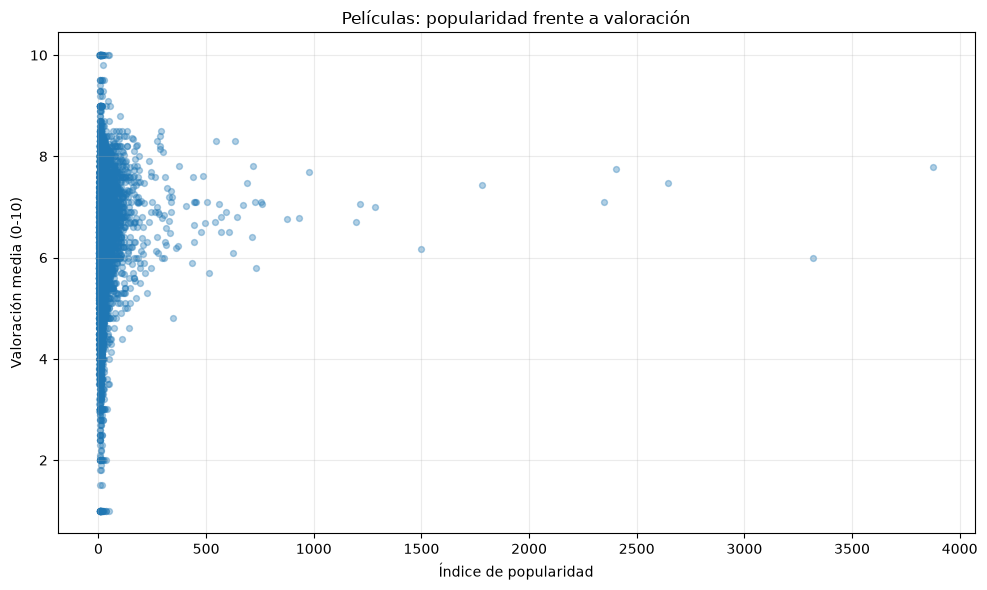

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    peliculas_analisis["popularity"],
    peliculas_analisis["vote_average_valid"],
    alpha=0.35,
    s=18
)

ax.set_title("Películas: popularidad frente a valoración")
ax.set_xlabel("Índice de popularidad")
ax.set_ylabel("Valoración media (0-10)")
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

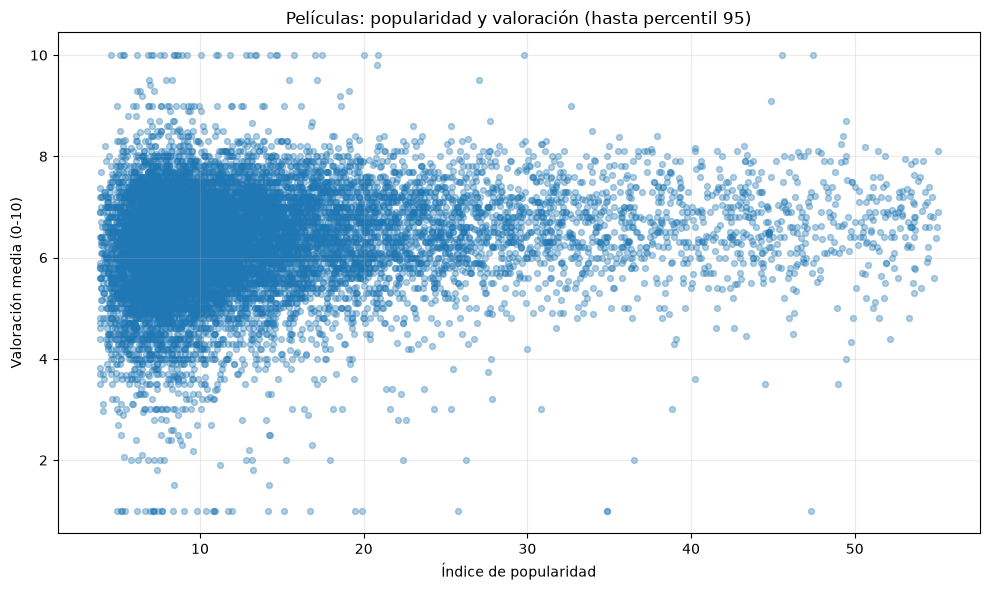

Umbral de popularidad (percentil 95): 55.09
Películas representadas: 15200 de 16000


In [23]:
import matplotlib.pyplot as plt

# Limitar la vista al percentil 95 de popularidad.
# Los datos originales permanecen intactos.
limite_popularidad = peliculas_analisis["popularity"].quantile(0.95)

peliculas_visibles = peliculas_analisis[
    peliculas_analisis["popularity"] <= limite_popularidad
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    peliculas_visibles["popularity"],
    peliculas_visibles["vote_average_valid"],
    alpha=0.35,
    s=18
)

ax.set_title("Películas: popularidad y valoración (hasta percentil 95)")
ax.set_xlabel("Índice de popularidad")
ax.set_ylabel("Valoración media (0-10)")
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print(f"Umbral de popularidad (percentil 95): {limite_popularidad:.2f}")
print(f"Películas representadas: {len(peliculas_visibles)} de {len(peliculas_analisis)}")

In [24]:
# Contar asociaciones entre títulos y géneros
top_generos = (
    generos_catalogo
    .groupby(["content_type", "genres"])
    .size()
    .reset_index(name="cantidad")
    .sort_values(
        ["content_type", "cantidad"],
        ascending=[True, False]
    )
)

print("=== TOP 10 GÉNEROS DE PELÍCULAS ===")
print(
    top_generos[top_generos["content_type"] == "Películas"]
    .head(10)[["genres", "cantidad"]]
    .to_string(index=False)
)

print("\n=== TOP 10 GÉNEROS DE SERIES ===")
print(
    top_generos[top_generos["content_type"] == "Series"]
    .head(10)[["genres", "cantidad"]]
    .to_string(index=False)
)

=== TOP 10 GÉNEROS DE PELÍCULAS ===
   genres  cantidad
    Drama      6910
   Comedy      4533
 Thriller      3769
   Action      3239
  Romance      2571
   Horror      2425
Adventure      1768
    Crime      1738
Animation      1579
   Family      1472

=== TOP 10 GÉNEROS DE SERIES ===
            genres  cantidad
             Drama      7863
            Comedy      4573
         Animation      2491
Action & Adventure      1988
  Sci-Fi & Fantasy      1958
           Reality      1631
            Family      1542
             Crime      1465
           Mystery      1333
       Documentary       909


### Distribución de géneros del catálogo

El análisis de géneros identifica a Drama como la categoría más frecuente tanto en películas, con 6.910 asociaciones, como en series, con 7.863. Comedy ocupa el segundo lugar en ambas categorías, con 4.533 asociaciones en películas y 4.573 en series.

En películas también destacan Thriller y Action, mientras que en series sobresalen Animation, Action & Adventure y Sci-Fi & Fantasy. Estos resultados permiten identificar diferencias en la composición del catálogo según el tipo de contenido y proporcionan una base para diseñar filtros y visualizaciones por género en los dashboards ejecutivo y analítico.

Debido a que los títulos pueden estar asociados a varios géneros, las frecuencias representan asociaciones título-género y no categorías mutuamente excluyentes. Por ello, los resultados describen la composición de los datos disponibles, pero no permiten inferir directamente preferencias de audiencia o niveles de visualización.

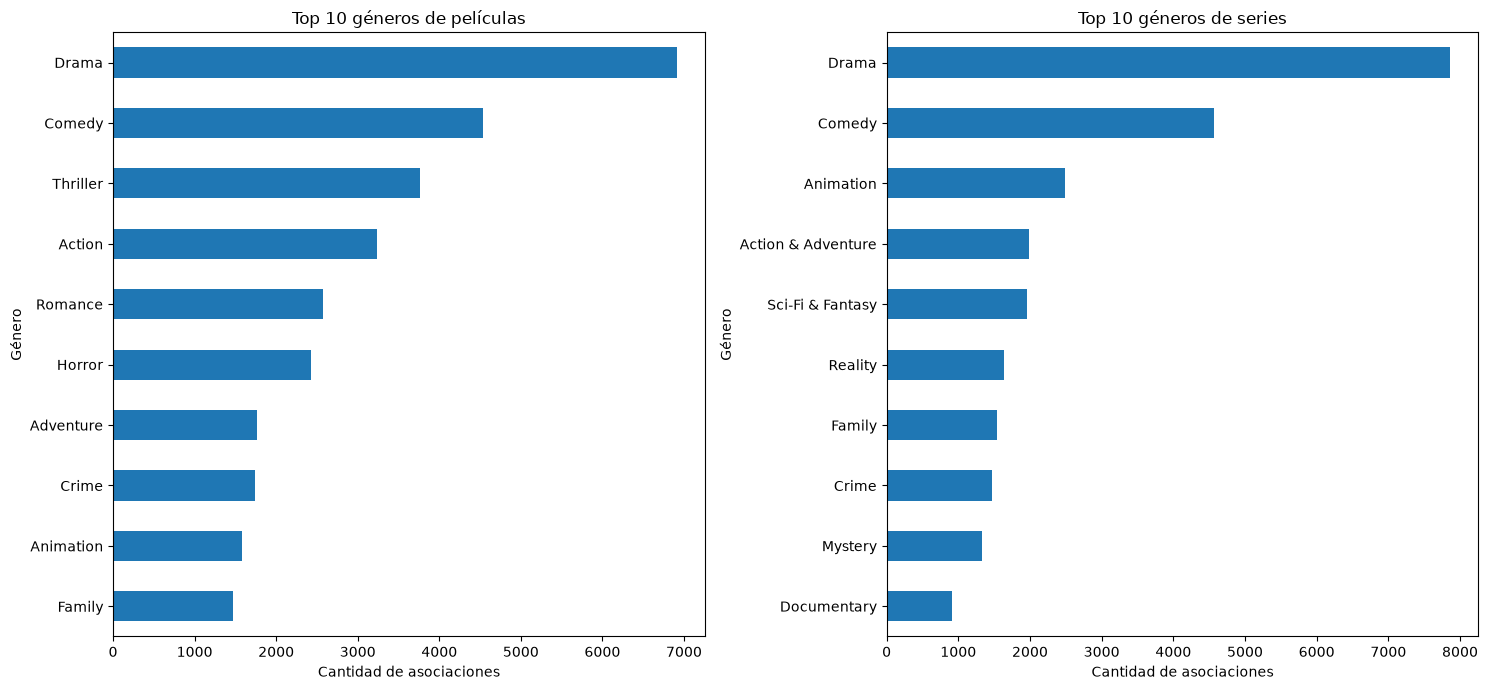

In [25]:
import matplotlib.pyplot as plt

top_10_peliculas = (
    generos_catalogo[generos_catalogo["content_type"] == "Películas"]
    ["genres"]
    .value_counts()
    .head(10)
    .sort_values()
)

top_10_series = (
    generos_catalogo[generos_catalogo["content_type"] == "Series"]
    ["genres"]
    .value_counts()
    .head(10)
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

top_10_peliculas.plot(
    kind="barh",
    ax=axes[0],
    title="Top 10 géneros de películas"
)
axes[0].set_xlabel("Cantidad de asociaciones")
axes[0].set_ylabel("Género")

top_10_series.plot(
    kind="barh",
    ax=axes[1],
    title="Top 10 géneros de series"
)
axes[1].set_xlabel("Cantidad de asociaciones")
axes[1].set_ylabel("Género")

plt.tight_layout()
plt.show()

tipo        Películas  Series
year_added                   
2010             1000    1000
2011             1000    1000
2012             1000    1000
2013             1000    1000
2014             1000    1000
2015             1000    1000
2016             1000    1000
2017             1000    1000
2018             1000    1000
2019             1000    1000
2020             1000    1000
2021             1000    1000
2022             1000    1000
2023             1000    1000
2024             1000    1000
2025             1000     991


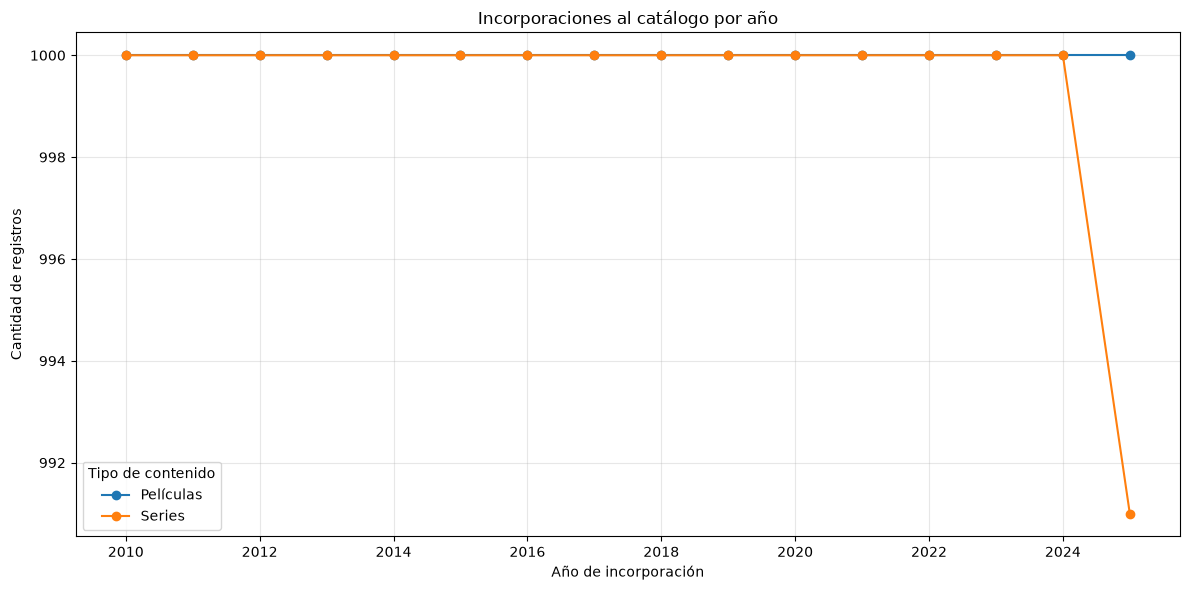

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# Combinar las fechas de incorporación de películas y series
incorporaciones = pd.concat([
    peliculas_analisis[["date_added"]].assign(tipo="Películas"),
    series_analisis[["date_added"]].assign(tipo="Series")
], ignore_index=True)

incorporaciones["date_added"] = pd.to_datetime(
    incorporaciones["date_added"],
    errors="coerce"
)

incorporaciones["year_added"] = incorporaciones["date_added"].dt.year

# Contar incorporaciones por año y tipo de contenido
conteo_anual = (
    incorporaciones
    .groupby(["year_added", "tipo"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print(conteo_anual.to_string())

# Gráfico comparativo
conteo_anual.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Incorporaciones al catálogo por año")
plt.xlabel("Año de incorporación")
plt.ylabel("Cantidad de registros")
plt.grid(True, alpha=0.3)
plt.legend(title="Tipo de contenido")
plt.tight_layout()
plt.show()

### Limitaciones del análisis temporal

El análisis de las fechas de incorporación muestra una distribución uniforme de 1.000 registros anuales por tipo de contenido entre 2010 y 2024. En 2025 se identifican 1.000 registros de películas y 991 de series. Esta regularidad podría estar relacionada con un criterio de selección o construcción del dataset, aunque la información disponible no permite confirmar su causa.

Por esta razón, la cantidad de registros por año no debe interpretarse directamente como una medida del crecimiento histórico del catálogo de Netflix. La visualización temporal se utilizará para describir los datos disponibles, considerando esta limitación en la interpretación de los resultados.

In [27]:
def contar_paises(df, tipo):
    datos = df[["show_id", "country"]].copy()

    datos["country"] = datos["country"].fillna("")
    datos["country"] = datos["country"].str.split(",")
    datos = datos.explode("country")

    datos["country"] = datos["country"].str.strip()
    datos = datos[datos["country"] != ""]

    datos["tipo"] = tipo

    return (
        datos.groupby(["tipo", "country"])["show_id"]
        .nunique()
        .reset_index(name="cantidad_titulos")
        .sort_values("cantidad_titulos", ascending=False)
    )


paises_peliculas = contar_paises(peliculas_analisis, "Películas")
paises_series = contar_paises(series_analisis, "Series")

print("=== TOP 10 PAÍSES: PELÍCULAS ===")
print(
    paises_peliculas.head(10)[["country", "cantidad_titulos"]]
    .to_string(index=False)
)

print("\n=== TOP 10 PAÍSES: SERIES ===")
print(
    paises_series.head(10)[["country", "cantidad_titulos"]]
    .to_string(index=False)
)

=== TOP 10 PAÍSES: PELÍCULAS ===
                 country  cantidad_titulos
United States of America              7762
          United Kingdom              1743
                  France              1701
                  Canada              1063
                   Japan               990
             South Korea               875
                 Germany               691
                   Spain               563
                   India               528
                 Belgium               515

=== TOP 10 PAÍSES: SERIES ===
                 country  cantidad_titulos
United States of America              3193
                   China              1900
                   Japan              1879
             South Korea              1299
          United Kingdom               865
                  Canada               652
                 Germany               469
                  France               407
             Philippines               401
                   India         

### Distribución geográfica del catálogo

El análisis geográfico identifica a Estados Unidos como el principal país asociado a los títulos del dataset, tanto en películas, con 7.762 títulos, como en series, con 3.193. En películas destacan también Reino Unido y Francia, mientras que en series sobresalen China y Japón, seguidos por Corea del Sur.

Las diferencias observadas muestran que la composición geográfica del catálogo varía según el tipo de contenido. Esta información permite incorporar comparaciones por país en los dashboards ejecutivo y analítico. No obstante, dado que un título puede estar asociado a varios países, las frecuencias no son mutuamente excluyentes y no deben interpretarse como medidas de audiencia o reproducciones.

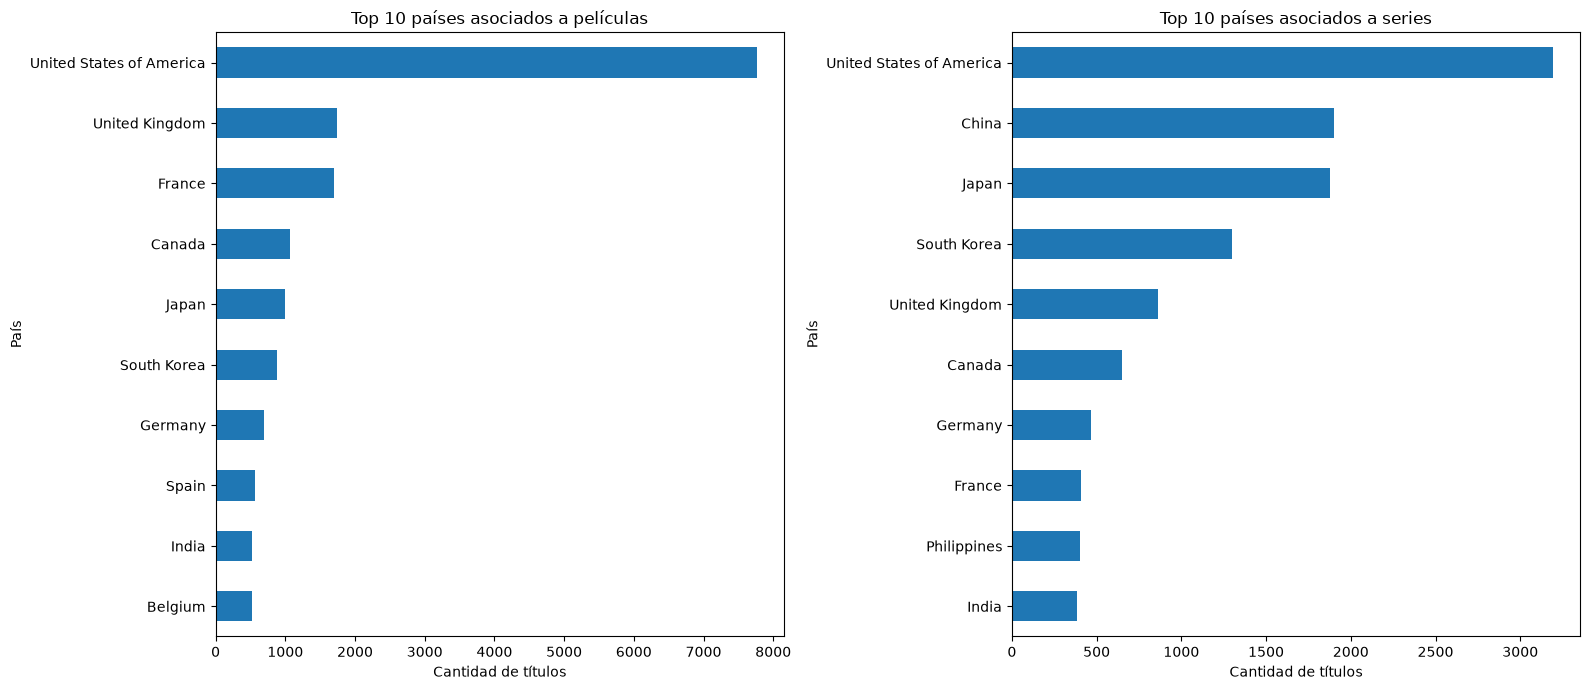

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

paises_peliculas.head(10).sort_values(
    "cantidad_titulos"
).plot(
    kind="barh",
    x="country",
    y="cantidad_titulos",
    ax=axes[0],
    legend=False,
    title="Top 10 países asociados a películas"
)

paises_series.head(10).sort_values(
    "cantidad_titulos"
).plot(
    kind="barh",
    x="country",
    y="cantidad_titulos",
    ax=axes[1],
    legend=False,
    title="Top 10 países asociados a series"
)

axes[0].set_xlabel("Cantidad de títulos")
axes[0].set_ylabel("País")
axes[1].set_xlabel("Cantidad de títulos")
axes[1].set_ylabel("País")

plt.tight_layout()
plt.show()

In [29]:
from pathlib import Path
import pandas as pd

# Carpeta donde guardaremos los resultados
carpeta_resultados = Path("../data/processed/resultados")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Exportar asociaciones entre títulos y géneros
generos_catalogo.to_csv(
    carpeta_resultados / "generos_catalogo.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar países asociados a películas y series
paises_combinados = pd.concat(
    [paises_peliculas, paises_series],
    ignore_index=True
)

paises_combinados.to_csv(
    carpeta_resultados / "paises_catalogo.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar resumen anual de incorporaciones
conteo_anual.to_csv(
    carpeta_resultados / "incorporaciones_anuales.csv",
    encoding="utf-8-sig"
)

print("Archivos exportados correctamente:")
for archivo in sorted(carpeta_resultados.glob("*.csv")):
    print(f"- {archivo.name}")

Archivos exportados correctamente:
- generos_catalogo.csv
- incorporaciones_anuales.csv
- paises_catalogo.csv


In [31]:

# KPI principales del catálogo para el dashboard ejecutivo

total_peliculas = len(peliculas_analisis)
total_series = len(series_analisis)
total_catalogo = total_peliculas + total_series

porcentaje_peliculas = total_peliculas / total_catalogo * 100
porcentaje_series = total_series / total_catalogo * 100

valoracion_peliculas = peliculas_analisis["vote_average_valid"].mean()
valoracion_series = series_analisis["vote_average_valid"].mean()

kpis = pd.DataFrame({
    "Indicador": [
        "Total de títulos",
        "Total de películas",
        "Total de series",
        "Porcentaje de películas",
        "Porcentaje de series",
        "Valoración media de películas",
        "Valoración media de series"
    ],
    "Valor": [
        total_catalogo,
        total_peliculas,
        total_series,
        round(porcentaje_peliculas, 2),
        round(porcentaje_series, 2),
        round(valoracion_peliculas, 2),
        round(valoracion_series, 2)
    ]
})

display(kpis)


ruta_kpis = carpeta_resultados / "kpis_ejecutivos.csv"

kpis.to_csv(
    ruta_kpis,
    index=False,
    encoding="utf-8-sig"
)

print(f"KPI exportados correctamente: {ruta_kpis}")


,Indicador,Valor
0,Total de títulos,31991.00
1,Total de películas,16000.00
2,Total de series,15991.00
3,Porcentaje de películas,50.01
4,Porcentaje de series,49.99
5,Valoración media de películas,6.31
6,Valoración media de series,7.03


KPI exportados correctamente: ..\data\processed\resultados\kpis_ejecutivos.csv


In [32]:

# Preparar datos para comparar popularidad y valoración

columnas_comparacion = [
    "show_id",
    "title",
    "type",
    "release_year",
    "genres",
    "popularity",
    "vote_average_valid",
    "vote_count"
]

comparacion_peliculas = peliculas_analisis[columnas_comparacion].copy()
comparacion_series = series_analisis[columnas_comparacion].copy()

comparacion_catalogo = pd.concat(
    [comparacion_peliculas, comparacion_series],
    ignore_index=True
)

# Excluir registros sin valoración válida para esta visualización
comparacion_catalogo = comparacion_catalogo.dropna(
    subset=["vote_average_valid", "popularity"]
)

ruta_comparacion = carpeta_resultados / "popularidad_vs_valoracion.csv"

comparacion_catalogo.to_csv(
    ruta_comparacion,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente:", ruta_comparacion)
print("Registros preparados:", len(comparacion_catalogo))
print("Tipos de contenido:")
print(comparacion_catalogo["type"].value_counts())


Archivo exportado correctamente: ..\data\processed\resultados\popularidad_vs_valoracion.csv
Registros preparados: 27414
Tipos de contenido:
type
Movie      15101
TV Show    12313
Name: count, dtype: int64


In [33]:

# Preparar ranking de los títulos mejor valorados

MIN_VOTOS_ESTRICTO = 500

columnas_ranking = [
    "show_id",
    "title",
    "type",
    "release_year",
    "genres",
    "vote_average_valid",
    "vote_count"
]

ranking_peliculas = peliculas_analisis[columnas_ranking].copy()
ranking_series = series_analisis[columnas_ranking].copy()

ranking_catalogo = pd.concat(
    [ranking_peliculas, ranking_series],
    ignore_index=True
)

ranking_catalogo = ranking_catalogo[
    (ranking_catalogo["vote_count"] >= MIN_VOTOS_ESTRICTO)
    & (ranking_catalogo["vote_average_valid"].notna())
].copy()

ranking_catalogo = ranking_catalogo.sort_values(
    ["type", "vote_average_valid", "vote_count"],
    ascending=[True, False, False]
)

top_10_peliculas = (
    ranking_catalogo[ranking_catalogo["type"] == "Movie"]
    .head(10)
)

top_10_series = (
    ranking_catalogo[ranking_catalogo["type"] == "TV Show"]
    .head(10)
)

top_10 = pd.concat(
    [top_10_peliculas, top_10_series],
    ignore_index=True
)

ruta_top10 = carpeta_resultados / "top10_titulos_valorados.csv"

top_10.to_csv(
    ruta_top10,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente:", ruta_top10)
print("\nTop 10 de películas:")
display(top_10_peliculas[[
    "title", "release_year", "vote_average_valid", "vote_count"
]])

print("\nTop 10 de series:")
display(top_10_series[[
    "title", "release_year", "vote_average_valid", "vote_count"
]])


Archivo exportado correctamente: ..\data\processed\resultados\top10_titulos_valorados.csv

Top 10 de películas:


,title,release_year,vote_average_valid,vote_count
4000,Interstellar,2014,8.500,36625
9002,Parasite,2019,8.500,18728
6007,Your Name.,2016,8.500,11613
10306,Gabriel's Inferno,2020,8.410,2417
4007,Whiplash,2014,8.400,15418
6032,A Silent Voice: The Movie,2016,8.400,4036
10641,Gabriel's Inferno: Part II,2020,8.400,1519
10105,Gabriel's Inferno: Part III,2020,8.400,1057
3170,Hope,2013,8.400,756
8003,Spider-Man: Into the Spider-Verse,2018,8.397,15936



Top 10 de series:


,title,release_year,vote_average_valid,vote_count
27017,Arcane,2021,8.800,4932
30059,Hazbin Hotel,2024,8.800,1229
19002,Rick and Morty,2013,8.700,9992
19087,Attack on Titan,2013,8.700,6603
25136,Demon Slayer: Kimetsu no Yaiba,2019,8.700,6585
21028,Better Call Saul,2015,8.700,5475
23095,Anne with an E,2017,8.700,4713
26018,The Owl House,2020,8.700,1643
25122,Chernobyl,2019,8.685,6636
18201,Kamisama Kiss,2012,8.648,928


In [34]:

# Preparar análisis financiero de películas

finanzas_peliculas = peliculas_analisis[
    (peliculas_analisis["budget"] > 0)
    & (peliculas_analisis["revenue"] > 0)
].copy()

# Indicador definido por el caso: ingresos / presupuesto
finanzas_peliculas["revenue_budget_ratio"] = (
    finanzas_peliculas["revenue"] / finanzas_peliculas["budget"]
)

columnas_financieras = [
    "show_id",
    "title",
    "release_year",
    "genres",
    "budget",
    "revenue",
    "revenue_budget_ratio",
    "popularity",
    "vote_average_valid",
    "vote_count"
]

finanzas_peliculas = finanzas_peliculas[columnas_financieras]

ruta_finanzas = carpeta_resultados / "analisis_financiero_peliculas.csv"

finanzas_peliculas.to_csv(
    ruta_finanzas,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente:", ruta_finanzas)
print("Películas con presupuesto e ingresos positivos:", len(finanzas_peliculas))

print("\nEstadísticas del indicador ingresos/presupuesto:")
display(finanzas_peliculas["revenue_budget_ratio"].describe().to_frame())


Archivo exportado correctamente: ..\data\processed\resultados\analisis_financiero_peliculas.csv
Películas con presupuesto e ingresos positivos: 3540

Estadísticas del indicador ingresos/presupuesto:


,revenue_budget_ratio
count,3.540000e+03
mean,7.815457e+02
std,4.155657e+04
min,7.800000e-06
25%,5.213043e-01
50%,1.700033e+00
75%,3.760963e+00
max,2.456760e+06


In [35]:

# KPI financieros para el dashboard analítico

total_peliculas_financieras = len(finanzas_peliculas)

presupuesto_medio = finanzas_peliculas["budget"].mean()
ingresos_medios = finanzas_peliculas["revenue"].mean()
mediana_ingresos_presupuesto = finanzas_peliculas["revenue_budget_ratio"].median()

peliculas_ratio_mayor_1 = (
    finanzas_peliculas["revenue_budget_ratio"] > 1
).sum()

porcentaje_ratio_mayor_1 = (
    peliculas_ratio_mayor_1 / total_peliculas_financieras * 100
)

kpis_financieros = pd.DataFrame({
    "Indicador": [
        "Películas con datos financieros válidos",
        "Presupuesto medio",
        "Ingresos medios",
        "Mediana ingresos/presupuesto",
        "Películas con ingresos superiores al presupuesto (%)"
    ],
    "Valor": [
        total_peliculas_financieras,
        round(presupuesto_medio, 2),
        round(ingresos_medios, 2),
        round(mediana_ingresos_presupuesto, 3),
        round(porcentaje_ratio_mayor_1, 2)
    ]
})

display(kpis_financieros)

ruta_kpis_financieros = (
    carpeta_resultados / "kpis_financieros.csv"
)

kpis_financieros.to_csv(
    ruta_kpis_financieros,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo exportado correctamente:", ruta_kpis_financieros)


,Indicador,Valor
0,Películas con datos financieros válidos,3.540000e+03
1,Presupuesto medio,3.558214e+07
2,Ingresos medios,1.037772e+08
3,Mediana ingresos/presupuesto,1.700000e+00
4,Películas con ingresos superiores al presupues...,6.316000e+01



Archivo exportado correctamente: ..\data\processed\resultados\kpis_financieros.csv


In [36]:

# Preparar evolución anual de incorporaciones al catálogo

catalogo_temporal = pd.concat([
    peliculas_analisis[["show_id", "title", "type", "date_added"]].copy(),
    series_analisis[["show_id", "title", "type", "date_added"]].copy()
], ignore_index=True)

catalogo_temporal["date_added"] = pd.to_datetime(
    catalogo_temporal["date_added"],
    errors="coerce"
)

catalogo_temporal["year_added"] = (
    catalogo_temporal["date_added"].dt.year
)

incorporaciones_anuales = (
    catalogo_temporal
    .dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .sort_values("year_added")
)

ruta_temporal = (
    carpeta_resultados / "incorporaciones_anuales_dashboard.csv"
)

incorporaciones_anuales.to_csv(
    ruta_temporal,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente:", ruta_temporal)
display(incorporaciones_anuales)


Archivo exportado correctamente: ..\data\processed\resultados\incorporaciones_anuales_dashboard.csv


type,year_added,Movie,TV Show
0,2010,1000,1000
1,2011,1000,1000
2,2012,1000,1000
3,2013,1000,1000
4,2014,1000,1000
5,2015,1000,1000
6,2016,1000,1000
7,2017,1000,1000
8,2018,1000,1000
9,2019,1000,1000


In [37]:

# Verificar los archivos preparados para los dashboards

for archivo in sorted(carpeta_resultados.glob("*.csv")):
    print(f"{archivo.name} — {archivo.stat().st_size / 1024:.1f} KB")


analisis_financiero_peliculas.csv — 347.5 KB
generos_catalogo.csv — 2815.3 KB
incorporaciones_anuales.csv — 0.3 KB
incorporaciones_anuales_dashboard.csv — 0.3 KB
kpis_ejecutivos.csv — 0.2 KB
kpis_financieros.csv — 0.2 KB
paises_catalogo.csv — 5.4 KB
popularidad_vs_valoracion.csv — 1944.0 KB
top10_titulos_valorados.csv — 1.6 KB
